In [1]:
import pandas as pd
from datetime import datetime 
from pandas import DataFrame
import numpy as np
from matplotlib import pyplot as plt

In [2]:
columnasDates = ['year', 'month', 'day', 'hour']
df = pd.read_csv('raw.csv') 
df['dates'] = pd.to_datetime(df[columnasDates])
df.drop(columns=columnasDates, inplace=True)
df.set_index('dates',inplace=True)

df.drop(columns=['No'], inplace=True)
df.columns = ['pollution', 'dew', 'temp', 'press', 'wnd_dir', 'wnd_spd', 'snow', 'rain']
df['pollution'] = df['pollution'].fillna(0)
#empieza en la fila 24 (recuerda que empieza contando en 0, practicamente empieza en la fila numero 25
df = df[24:]
df.head()

,pollution,dew,temp,press,wnd_dir,wnd_spd,snow,rain
dates,,,,,,,,
2010-01-02 00:00:00,129.0,-16,-4.0,1020.0,SE,1.79,0,0
2010-01-02 01:00:00,148.0,-15,-4.0,1020.0,SE,2.68,0,0
2010-01-02 02:00:00,159.0,-11,-5.0,1021.0,SE,3.57,0,0
2010-01-02 03:00:00,181.0,-7,-5.0,1022.0,SE,5.36,1,0
2010-01-02 04:00:00,138.0,-7,-5.0,1022.0,SE,6.25,2,0


In [3]:
print(df.shape)
print(df.shape[0]/24)#cantidad de dias
print((df.shape[0]/24)/365)#cantidad de anios
print(365*24) #registros por anio

(43800, 8)
1825.0
5.0
8760


### Analisis Exploratorio

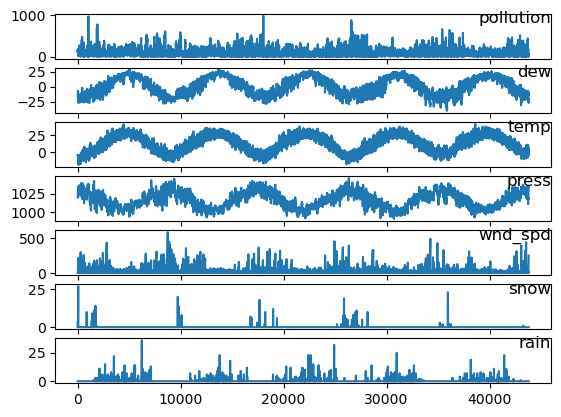

In [4]:
from matplotlib import pyplot as plt
values = df.values
groups = [0, 1, 2, 3, 5, 6, 7]
i = 1

for group in groups:
    plt.subplot(len(groups), 1, i)
    plt.plot(values[:, group])
    plt.title(f'{df.columns[group]}', y=0.6,loc='right')
    i+=1

plt.show()

In [5]:
# serie de numpy
#adelante: cuanto se necesita
def datos_a_supervisado(datos, atras=1, adelante=1, dropnan=True):
    n_vars = 1 if type(datos) is list else datos.shape[1]
    df = DataFrame(datos)
    cols, names = [], []
    for i in range (atras, 0,-1):
        cols.append(df.shift(i))
        names += [f'var{j+1}(t-{i})'for j in range(n_vars)]
    for i in range (0,adelante):
        cols.append(df.shift(-i))
        if (i == 0):
            names += [f'var{j+1}(t)' for j in range(n_vars)]
        else:
            names += [f'var{j+1}(t{i})' for j in range(n_vars)]
    agg = pd.concat(cols, axis=1) #Esto lo agrega en la derecha, no abajo, ojito
    agg.columns = names
    #print(agg)
    if dropnan:
        agg.dropna(inplace=True)
    return agg
        

In [6]:
#TEST
matriz = np.array([
    [1, 10],   # Fila 0
    [2, 20],   # Fila 1
    [3, 30],
    [4, 40]
])

datos_a_supervisado(matriz,2,1)

,var1(t-2),var2(t-2),var1(t-1),var2(t-1),var1(t),var2(t)
2,1.0,10.0,2.0,20.0,3,30
3,2.0,20.0,3.0,30.0,4,40


In [7]:
df.head()

,pollution,dew,temp,press,wnd_dir,wnd_spd,snow,rain
dates,,,,,,,,
2010-01-02 00:00:00,129.0,-16,-4.0,1020.0,SE,1.79,0,0
2010-01-02 01:00:00,148.0,-15,-4.0,1020.0,SE,2.68,0,0
2010-01-02 02:00:00,159.0,-11,-5.0,1021.0,SE,3.57,0,0
2010-01-02 03:00:00,181.0,-7,-5.0,1022.0,SE,5.36,1,0
2010-01-02 04:00:00,138.0,-7,-5.0,1022.0,SE,6.25,2,0


In [8]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error

values = df.values
encoder = LabelEncoder() #Pasar a numerooos etiquetas con texto!!!,
values[:,4] = encoder.fit_transform(values[:,4])  #Selecciona la columna de direccion de 
#del viento para convertirlo en variables categoricas nominales 
values = values.astype('float32')
scaler = MinMaxScaler(feature_range =(0,1)) #Min max 

listaTran = scaler.fit_transform(values) 
print(listaTran[:3,:])

[[0.12977867 0.35294122 0.24590163 0.5272732  0.6666667  0.00229001
  0.         0.        ]
 [0.14889336 0.36764708 0.24590163 0.5272732  0.6666667  0.00381099
  0.         0.        ]
 [0.15995975 0.4264706  0.22950819 0.545454   0.6666667  0.00533197
  0.         0.        ]]


In [9]:
print(listaTran.shape)
print(listaTran[:,-8]) #Esta es la fila de pollution, puedes ver que los valores
#coinciden con los de arriba, en todo caso, hazlo bien jejej 

(43800, 8)
[0.12977867 0.14889336 0.15995975 ... 0.01006036 0.00804829 0.01207243]


In [10]:
#Hasta aqui todo lo que se ha hecho a sido normalizar, finalmente se usa la funcion

'''Variables importantes que debes de usar en el futuro'''
horas_atras = 1
horas_adelante = 1 
n_variables = 8 

cambiado = datos_a_supervisado(listaTran, horas_atras, horas_adelante)
cambiado.head()

,var1(t-1),var2(t-1),var3(t-1),var4(t-1),var5(t-1),var6(t-1),var7(t-1),var8(t-1),var1(t),var2(t),var3(t),var4(t),var5(t),var6(t),var7(t),var8(t)
1,0.129779,0.352941,0.245902,0.527273,0.666667,0.002290,0.000000,0.0,0.148893,0.367647,0.245902,0.527273,0.666667,0.003811,0.000000,0.0
2,0.148893,0.367647,0.245902,0.527273,0.666667,0.003811,0.000000,0.0,0.159960,0.426471,0.229508,0.545454,0.666667,0.005332,0.000000,0.0
3,0.159960,0.426471,0.229508,0.545454,0.666667,0.005332,0.000000,0.0,0.182093,0.485294,0.229508,0.563637,0.666667,0.008391,0.037037,0.0
4,0.182093,0.485294,0.229508,0.563637,0.666667,0.008391,0.037037,0.0,0.138833,0.485294,0.229508,0.563637,0.666667,0.009912,0.074074,0.0
5,0.138833,0.485294,0.229508,0.563637,0.666667,0.009912,0.074074,0.0,0.109658,0.485294,0.213115,0.563637,0.666667,0.011433,0.111111,0.0


In [11]:
values=cambiado.values
values[:,-8] # Columna var1(t): contaminación de la hora actual, la variable a predecir.
              # Cada fila tiene las 8 variables de la hora anterior (t-1) y esta columna (t)

array([0.14889336, 0.15995975, 0.18209255, ..., 0.01006036, 0.00804829,
       0.01207243], dtype=float32)

In [12]:
#Solo funciona para una hora adelante
cuantos = [i for i in range(horas_atras*8+1, (horas_atras+horas_adelante)*8 )]
print(cuantos)
#En esta etapa estamos borrando todos las columnas de la siguiente fecha que queremos predecir (No usamos estos datos para entrenar
# Ya que nos interesa predecir con los datos anteriores no con los actuales 
cambiado.drop(cambiado.columns[cuantos], axis=1,inplace=True)

[9, 10, 11, 12, 13, 14, 15]


In [13]:
cambiado.head()

,var1(t-1),var2(t-1),var3(t-1),var4(t-1),var5(t-1),var6(t-1),var7(t-1),var8(t-1),var1(t)
1,0.129779,0.352941,0.245902,0.527273,0.666667,0.002290,0.000000,0.0,0.148893
2,0.148893,0.367647,0.245902,0.527273,0.666667,0.003811,0.000000,0.0,0.159960
3,0.159960,0.426471,0.229508,0.545454,0.666667,0.005332,0.000000,0.0,0.182093
4,0.182093,0.485294,0.229508,0.563637,0.666667,0.008391,0.037037,0.0,0.138833
5,0.138833,0.485294,0.229508,0.563637,0.666667,0.009912,0.074074,0.0,0.109658


In [14]:
values = cambiado.values
datos_para_entrenar = 365*24 #Cantidad de datos que se usan 

train = values[:datos_para_entrenar,:] #Se seleccionaron hasta la cantidad deseada de entrenamiento
#Recuerda [(incluye):(excluye) ,(incluye):(excluye)]
test = values[datos_para_entrenar:,:] #Se selecciona desde la cantidad hasta el final (filas)

#Selecciona todas las columnas menos la ultima columna la cual tratamos de predecir
train_X, train_y = train[: , :-1], train[: , -1] #Uno es un array numpy 2d, el otro es un array 1d numpy
test_X, test_y = test[: , :-1], test[: , -1]
print(train_X.shape, train_y.shape, test_X.shape, test_y.shape)
#en base a esto se tiene una proporcion mucho mas grande de datos de test que de training

(8760, 8) (8760,) (35039, 8) (35039,)


In [15]:
#Ahora para realizar LSTM se necesita un array 3D
#Por la naturaleza de LSTM se necesita la siguiente estructura para predecir:

# (muestras, pasos de tiempo, variables)
# (samples,  timesteps,       features)
train_X = train_X.reshape((train_X.shape[0], 1, train_X.shape[1])) 
# Así que pasa de (8760, 8) a (8760, 1, 8). 
#Cada hora, que era una fila de 8 números, 
#ahora es una mini-tabla de 1 fila × 8 columnas.
test_X = test_X.reshape((test_X.shape[0], 1, test_X.shape[1]))
print(train_X.shape, train_y.shape, test_X.shape, test_y.shape)
'''No volver a tocar mas de una vez, JAMAS, NADA, 
SI LO CORRES DE NUEVO TRATA DE hacer un array 3D 
del que ya existe!!!''' 

(8760, 1, 8) (8760,) (35039, 1, 8) (35039,)


'No volver a tocar mas de una vez, JAMAS, NADA, \nSI LO CORRES DE NUEVO TRATA DE hacer un array 3D \ndel que ya existe!!!'

In [16]:
from keras.models import Sequential
from keras.layers import Input, LSTM, Dense
#No he revisado nada desde aqui, pero entiendo lo basico, tengo que revisarlo mas y mas.
#Crea un modelo secuencial, los datos pasan en pila uno despues de otro
model = Sequential()
#Aqui se necesita saber la forma de cada ejemplo, no de todos los ejemplos, por eso index 1 y 2 
#Cada secuencia que procesarás tiene train_X.shape[1] pasos temporales (timesteps) 
# y train_X.shape[2] variables/características en cada paso
model.add(Input(shape=(train_X.shape[1], train_X.shape[2])))
#unidades de memoria
model.add(LSTM(50))
#Una neurona de salida 
model.add(Dense(1))
#loss = Mean Absolute Error y optimizer = Algoritmo que actualiza los pesos de las neuronas 
model.compile(loss='mae', optimizer='adam')

In [17]:
#'loss' es el error promedio (MAE, porque así lo pusiste en compile) sobre todos los datos de entrenamiento en esa época
#'val_loss' es el error promedio sobre todos los datos de prueba (test_X, test_y), 
#que el modelo nunca usa para aprender, solo para evaluarse.
#Cada número es el promedio de |valor real − predicción| de miles de datos, condensado en uno solo.

history = model.fit(train_X, train_y, epochs=50, batch_size=72, validation_data=(test_X, test_y), verbose=2, shuffle=False)
# plot history

'''En cuanto a esto tambien tener cuidado
Solo correr una vez, si algo de plt se rompe o algo mas abajo se rompe
correr todo desde el principio de nuevo, o si no entrenaras al mismo
modelo mas de una vez!!!''' 

Epoch 1/50
122/122 - 2s - 12ms/step - loss: 0.0541 - val_loss: 0.0724
Epoch 2/50
122/122 - 0s - 4ms/step - loss: 0.0370 - val_loss: 0.0769
Epoch 3/50
122/122 - 0s - 4ms/step - loss: 0.0235 - val_loss: 0.0665
Epoch 4/50
122/122 - 0s - 4ms/step - loss: 0.0182 - val_loss: 0.0559
Epoch 5/50
122/122 - 0s - 4ms/step - loss: 0.0164 - val_loss: 0.0430
Epoch 6/50
122/122 - 0s - 4ms/step - loss: 0.0156 - val_loss: 0.0310
Epoch 7/50
122/122 - 0s - 4ms/step - loss: 0.0150 - val_loss: 0.0240
Epoch 8/50
122/122 - 0s - 4ms/step - loss: 0.0149 - val_loss: 0.0219
Epoch 9/50
122/122 - 0s - 4ms/step - loss: 0.0148 - val_loss: 0.0195
Epoch 10/50
122/122 - 0s - 4ms/step - loss: 0.0149 - val_loss: 0.0180
Epoch 11/50
122/122 - 0s - 4ms/step - loss: 0.0147 - val_loss: 0.0168
Epoch 12/50
122/122 - 0s - 4ms/step - loss: 0.0147 - val_loss: 0.0153
Epoch 13/50
122/122 - 0s - 4ms/step - loss: 0.0146 - val_loss: 0.0152
Epoch 14/50
122/122 - 1s - 4ms/step - loss: 0.0145 - val_loss: 0.0149
Epoch 15/50
122/122 - 0s - 4

'En cuanto a esto tambien tener cuidado\nSolo correr una vez, si algo de plt se rompe o algo mas abajo se rompe\ncorrer todo desde el principio de nuevo, o si no entrenaras al mismo\nmodelo mas de una vez!!!'

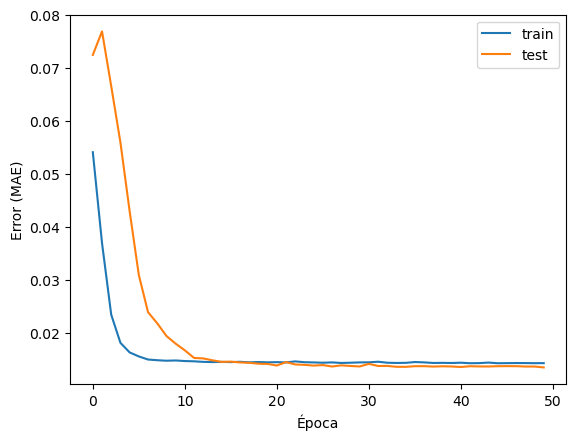

In [18]:

plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.xlabel('Época')
plt.ylabel('Error (MAE)')
plt.legend()
plt.show()

In [19]:
#Ignorar todo esto, solo es un mini formulario
'''
1D a 2D: 
y = train[:, -1]
# Opción 1: añadir una dimensión como columna
y_2d = y.reshape(-1, 1)
# Opción 2: usar newaxis
y_2d = y[:, np.newaxis]
2D a 1D:
y = train[:, -1:]
# Opción 1: seleccionar la primera (y única) columna
y_1d = y[:, 0]
# Opción 2: eliminar dimensiones de tamaño 1
y_1d = y.squeeze()
'''

'\n1D a 2D: \ny = train[:, -1]\n# Opción 1: añadir una dimensión como columna\ny_2d = y.reshape(-1, 1)\n# Opción 2: usar newaxis\ny_2d = y[:, np.newaxis]\n2D a 1D:\ny = train[:, -1:]\n# Opción 1: seleccionar la primera (y única) columna\ny_1d = y[:, 0]\n# Opción 2: eliminar dimensiones de tamaño 1\ny_1d = y.squeeze()\n'

In [20]:
#Ahora con 3 horas, sin mirar el archivo ese, solo con lo que ya sabes: 
values = df.values
encoder = LabelEncoder()
values[:,4] = encoder.fit_transform(values[:,4]) #Columna 4, direccion de viento 
#Ya que la columna tenia texto el array de numpy se convirtio en un array de objetos
#para hacer el mixmax se necesita decimales
values.astype('float32')
scale = MinMaxScaler(feature_range=(0,1))

listaTransformada = scale.fit_transform(values) 

In [21]:
df.head()

,pollution,dew,temp,press,wnd_dir,wnd_spd,snow,rain
dates,,,,,,,,
2010-01-02 00:00:00,129.0,-16,-4.0,1020.0,SE,1.79,0,0
2010-01-02 01:00:00,148.0,-15,-4.0,1020.0,SE,2.68,0,0
2010-01-02 02:00:00,159.0,-11,-5.0,1021.0,SE,3.57,0,0
2010-01-02 03:00:00,181.0,-7,-5.0,1022.0,SE,5.36,1,0
2010-01-02 04:00:00,138.0,-7,-5.0,1022.0,SE,6.25,2,0


In [22]:
print(listaTransformada.shape[0])
print(listaTransformada[:5,:])

43800
[[0.12977867 0.35294118 0.24590164 0.52727273 0.66666667 0.00229001
  0.         0.        ]
 [0.14889336 0.36764706 0.24590164 0.52727273 0.66666667 0.00381099
  0.         0.        ]
 [0.15995976 0.42647059 0.2295082  0.54545455 0.66666667 0.00533197
  0.         0.        ]
 [0.18209256 0.48529412 0.2295082  0.56363636 0.66666667 0.00839101
  0.03703704 0.        ]
 [0.138833   0.48529412 0.2295082  0.56363636 0.66666667 0.00991199
  0.07407407 0.        ]]


In [23]:
listaTransformada[:,-8]
#recuerda esto la primera columna pertence a la contaminacion en tal hora

array([0.12977867, 0.14889336, 0.15995976, ..., 0.01006036, 0.00804829,
       0.01207243])

In [24]:
atrasEn = 3 
adelanteEn = 1 
datosF = datos_a_supervisado(listaTransformada, atrasEn, adelanteEn)
datosF.head()

,var1(t-3),var2(t-3),var3(t-3),var4(t-3),var5(t-3),var6(t-3),var7(t-3),var8(t-3),var1(t-2),var2(t-2),...,var7(t-1),var8(t-1),var1(t),var2(t),var3(t),var4(t),var5(t),var6(t),var7(t),var8(t)
3,0.129779,0.352941,0.245902,0.527273,0.666667,0.002290,0.000000,0.0,0.148893,0.367647,...,0.000000,0.0,0.182093,0.485294,0.229508,0.563636,0.666667,0.008391,0.037037,0.0
4,0.148893,0.367647,0.245902,0.527273,0.666667,0.003811,0.000000,0.0,0.159960,0.426471,...,0.037037,0.0,0.138833,0.485294,0.229508,0.563636,0.666667,0.009912,0.074074,0.0
5,0.159960,0.426471,0.229508,0.545455,0.666667,0.005332,0.000000,0.0,0.182093,0.485294,...,0.074074,0.0,0.109658,0.485294,0.213115,0.563636,0.666667,0.011433,0.111111,0.0
6,0.182093,0.485294,0.229508,0.563636,0.666667,0.008391,0.037037,0.0,0.138833,0.485294,...,0.111111,0.0,0.105634,0.485294,0.213115,0.581818,0.666667,0.014492,0.148148,0.0
7,0.138833,0.485294,0.229508,0.563636,0.666667,0.009912,0.074074,0.0,0.109658,0.485294,...,0.148148,0.0,0.124748,0.485294,0.229508,0.600000,0.666667,0.017551,0.000000,0.0


In [25]:
#Solo funciona para una hora adelante
cuantos = [i for i in range(adelanteEn*8 + 1, (atrasEn+adelanteEn)*8 )]
print(cuantos)
#En esta etapa estamos borrando todos las columnas de la siguiente fecha que queremos predecir (No usamos estos datos para entrenar
# Ya que nos interesa predecir con los datos anteriores no con los actuales 
datosF.drop(datosF.columns[cuantos], axis=1,inplace=True)

[9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]


In [26]:
datosF.head()

,var1(t-3),var2(t-3),var3(t-3),var4(t-3),var5(t-3),var6(t-3),var7(t-3),var8(t-3),var1(t-2)
3,0.129779,0.352941,0.245902,0.527273,0.666667,0.002290,0.000000,0.0,0.148893
4,0.148893,0.367647,0.245902,0.527273,0.666667,0.003811,0.000000,0.0,0.159960
5,0.159960,0.426471,0.229508,0.545455,0.666667,0.005332,0.000000,0.0,0.182093
6,0.182093,0.485294,0.229508,0.563636,0.666667,0.008391,0.037037,0.0,0.138833
7,0.138833,0.485294,0.229508,0.563636,0.666667,0.009912,0.074074,0.0,0.109658


In [27]:
values = datosF.values
datos_para_entrenar = 730*24 #Cantidad de datos que se usan 
train = values[:datos_para_entrenar,:] 
test = values[datos_para_entrenar:,:]
train_X, train_y = train[: , :-1], train[: , -1]
test_X, test_y = test[: , :-1], test[: , -1]
print(train_X.shape, train_y.shape, test_X.shape, test_y.shape)

(17520, 8) (17520,) (26277, 8) (26277,)


In [28]:
train_X = train_X.reshape((train_X.shape[0], 1, train_X.shape[1])) 
test_X = test_X.reshape((test_X.shape[0], 1, test_X.shape[1]))
print(train_X.shape, train_y.shape, test_X.shape, test_y.shape)

(17520, 1, 8) (17520,) (26277, 1, 8) (26277,)


In [29]:
model = Sequential()
model.add(Input(shape=(train_X.shape[1], train_X.shape[2])))
model.add(LSTM(50))
model.add(Dense(1))
model.compile(loss='mae', optimizer='adam')

Epoch 1/80
244/244 - 1s - 6ms/step - loss: 0.0475 - val_loss: 0.0589
Epoch 2/80
244/244 - 1s - 2ms/step - loss: 0.0186 - val_loss: 0.0302
Epoch 3/80
244/244 - 1s - 2ms/step - loss: 0.0152 - val_loss: 0.0226
Epoch 4/80
244/244 - 1s - 2ms/step - loss: 0.0147 - val_loss: 0.0195
Epoch 5/80
244/244 - 1s - 2ms/step - loss: 0.0145 - val_loss: 0.0184
Epoch 6/80
244/244 - 1s - 2ms/step - loss: 0.0145 - val_loss: 0.0170
Epoch 7/80
244/244 - 1s - 2ms/step - loss: 0.0144 - val_loss: 0.0165
Epoch 8/80
244/244 - 1s - 2ms/step - loss: 0.0143 - val_loss: 0.0169
Epoch 9/80
244/244 - 1s - 2ms/step - loss: 0.0143 - val_loss: 0.0160
Epoch 10/80
244/244 - 1s - 2ms/step - loss: 0.0143 - val_loss: 0.0162
Epoch 11/80
244/244 - 1s - 2ms/step - loss: 0.0144 - val_loss: 0.0162
Epoch 12/80
244/244 - 1s - 2ms/step - loss: 0.0143 - val_loss: 0.0160
Epoch 13/80
244/244 - 1s - 2ms/step - loss: 0.0143 - val_loss: 0.0158
Epoch 14/80
244/244 - 1s - 2ms/step - loss: 0.0143 - val_loss: 0.0161
Epoch 15/80
244/244 - 1s - 2m

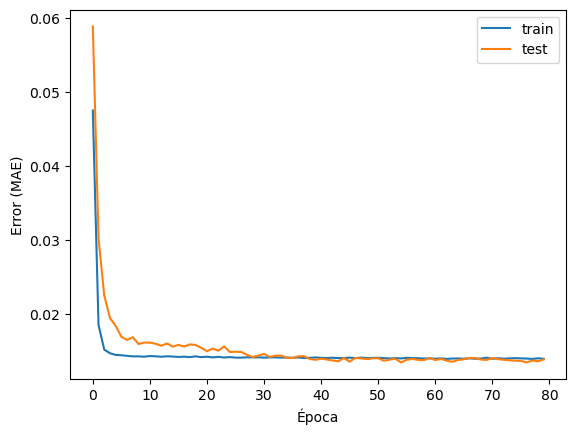

In [30]:
history = model.fit(train_X, train_y, epochs=80, batch_size=72, validation_data=(test_X, test_y), verbose=2, shuffle=False)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.xlabel('Época')
plt.ylabel('Error (MAE)')
plt.legend()
plt.show()